In [1]:
# Load packages
from sklearn.preprocessing import StandardScaler
from functools import reduce
import pandas as pd 
import numpy as np 
import os 

# Set workspace environment variables
os.environ["WORKSPACE_BUCKET"] = "gs://rw-migration-aou-rw-9f879fc4"
os.environ["ARTIFACT_REGISTRY_DOCKER_REPO"] = (
        "us-central1-docker.pkg.dev/all-of-us-rw-prod/aou-rw-gar-remote-repo-docker-prod"
)

# Load the remaining workspace environment settings
%run Setting_Env_Variables.ipynb

Successfully set WORKSPACE_CDR to: wb-silky-artichoke-2408.C2024Q3R9
Found bucket: id=dataproc-staging-aou-rw-9f879fc4, bucketName=dataproc-staging-wb-fast-radish-6415
Found bucket: id=dataproc-temp-aou-rw-9f879fc4, bucketName=dataproc-temp-wb-fast-radish-6415
Found bucket: id=rw-migration-aou-rw-9f879fc4, bucketName=rw-migration-aou-rw-9f879fc4

Variables extracted:
GOOGLE_CLOUD_PROJECT: wb-fast-radish-6415
WORKSPACE_BUCKET: gs://rw-migration-aou-rw-9f879fc4
WORKSPACE_TEMP_BUCKET: NOT FOUND
WORKSPACE_CDR: wb-silky-artichoke-2408.C2024Q3R9

✅ Saved to /home/jupyter/.bashrc
C2024Q3R9 BQ_DATASET
JupyterLab_Spark_cluster_for_AoU_Spark_20261006 DATAPROC_CLUSTER
dataproc-staging-aou-rw-9f879fc4 GCS_BUCKET
dataproc-temp-aou-rw-9f879fc4 GCS_BUCKET
rw-migration-aou-rw-9f879fc4 GCS_BUCKET
GOOGLE_CLOUD_PROJECT = wb-fast-radish-6415
WORKSPACE_BUCKET = gs://rw-migration-aou-rw-9f879fc4
wb-silky-artichoke-2408.C2024Q3R9



In [2]:
# List of genes of interest
gene = ['ENSG00000119772', 
        'ENSG00000168769', 
        'ENSG00000182054', 
        'ENSG00000161547']

# Assign bucket 
bucket = os.environ["WORKSPACE_BUCKET"]

# Functions 
def extract(df, gene): 
    '''
    Extracts variant information from saige-gene+ annotation table 
    df : saige-gene+ annoation table 
    gene : list of gene of interest 
    '''
    df = df[df[0].str.contains("|".join(gene), na=False)]
    df = df[0].str.split(' ', expand=True)
    df = df.drop(columns=0).T
    df.columns = df.iloc[0]
    df = df.iloc[1:].reset_index(drop=True)
    return df 

# List of variant ids 
ids, annotations = [], []

# Loop through each chromosome 
for chrom in [2, 4, 15, 17]:
    # GCS path
    gcs_path = (
        f"{bucket}/data/annotation_table/"
        f"EUR_HC_annotation/HC-annotation-chr{chrom}.txt"
    )

    # Local filename
    local_path = f"HC-annotation-chr{chrom}.txt"

    # Download using gcloud
    subprocess.run(
        ["gcloud", "storage", "cp", gcs_path, local_path],
        check=True
    )

    # Load annotation file 
    annotation = pd.read_csv(local_path, 
                             sep='\t', 
                             header=None)
    # Extract variant infomraiton 
    annotation = extract(annotation, gene)
    
    # Append variatn information to list 
    ids.append(annotation['var'])
    annotations.append(annotation)

# Concatenate variant information 
ids = np.array(pd.concat(ids))
annotations = pd.concat(annotations)

# Filter for loss of function 
lof = annotations[annotations['anno'].str.contains('LOFTEE-HC|SpliceAI-0.8')]
# Filter for missense 
missense = annotations[annotations['anno'].str.contains('AlphaMissense-0.564')]


Copying gs://rw-migration-aou-rw-9f879fc4/data/annotation_table/EUR_HC_annotation/HC-annotation-chr2.txt to file://HC-annotation-chr2.txt
  
............

Average throughput: 41.0MiB/s
Copying gs://rw-migration-aou-rw-9f879fc4/data/annotation_table/EUR_HC_annotation/HC-annotation-chr4.txt to file://HC-annotation-chr4.txt
  
..........

Average throughput: 28.9MiB/s
Copying gs://rw-migration-aou-rw-9f879fc4/data/annotation_table/EUR_HC_annotation/HC-annotation-chr15.txt to file://HC-annotation-chr15.txt
  
.........

Average throughput: 27.6MiB/s
Copying gs://rw-migration-aou-rw-9f879fc4/data/annotation_table/EUR_HC_annotation/HC-annotation-chr17.txt to file://HC-annotation-chr17.txt
  
............

Average throughput: 38.6MiB/s


In [3]:
# Load packages  
import os
import pandas as pd
import gcsfs
import ast
import re

# Functions 
def format(df): 
        '''
        Formats hail qc file 
        df : hail file for joint-call qc filters 
        '''
        df["alleles"] = df["alleles"].apply(ast.literal_eval)
        df["ref"] = df["alleles"].str[0]
        df["alt"] = df["alleles"].str[1]
        df['id'] = df['locus'] + ':' + df['ref'] + ':' + df['alt']
        df = df[['id', 's', 'DP', 'VAF', 'AB', 'GT', 'AD', 'GQ', 'PS', 'RGQ', 'FT']]
        return df 


# GCS path
gcs_path = f'{os.environ["WORKSPACE_BUCKET"]}/data/hail/'

# List files in GCS path
result = subprocess.run(
    ["gcloud", "storage", "ls", gcs_path],
    check=True,
    capture_output=True,
    text=True
)

# Format paths 
paths = result.stdout.strip().splitlines()

# Keep only variant_genotype_information files
variant_paths = [
    path for path in paths
    if "variant_genotype_information_chr" in path
]

# List of qc variants 
qc = [] 

# Loop through each file pat h
for path in variant_paths:
    print(path)

    # Local filename
    local_path = f"tmp.txt.gz"

    # Download using gcloud
    subprocess.run(
        ["gcloud", "storage", "cp", path, local_path],
        check=True
    )
    df = pd.read_csv(
            local_path,
            sep='\t',
            compression='gzip'
        )

    # Format dataframe 
    df = format(df) 
    # Append dataframe
    qc.append(df) 

# Concatenate dataframes 
qc = pd.concat(qc)

# Filter for PASS quality control 
qc = qc[qc['FT'] =='PASS']

# Filter for variants in annotaiton file 
subset_qc = qc[qc['id'].isin(ids)]

# Filter for allele balance and read depth 
filtered_qc = subset_qc[(subset_qc['AB'] > 0.35) & (subset_qc['DP'] > 20)]

/opt/conda/envs/jupyter/lib/python3.12/site-packages/google/api_core/_python_package_support.py:206: FutureWarning: Package google.api_core depends on grpcio, currently installed at version 1.78.1. grpcio < 1.83.0 does not support Post-Quantum Cryptography (PQC). Support for non-PQC environments is deprecated. In April 2027, Google Cloud Python packages will raise their minimum requirements (including google-api-core, grpcio, and grpcio-status) to enforce grpcio >= 1.83.0. For more details on Google Cloud's post-quantum security migration, visit: https://cloud.google.com/security/resources/post-quantum-cryptography
  warnings.warn(
/opt/conda/envs/jupyter/lib/python3.12/site-packages/google/auth/transport/grpc.py:43: FutureWarning: grpcio < 1.83.0 does not support Post-Quantum Cryptography (PQC). Support for non-PQC environments is deprecated. In April 2027, google-auth will raise its minimum requirements to enforce grpcio >= 1.83.0. For more details on Google Cloud's post-quantum secu

gs://rw-migration-aou-rw-9f879fc4/data/hail/variant_genotype_information_chr15_90080000_90110000.tsv.bgz


Copying gs://rw-migration-aou-rw-9f879fc4/data/hail/variant_genotype_information_chr15_90080000_90110000.tsv.bgz to file://tmp.txt.gz
  
...........

Average throughput: 56.1MiB/s


gs://rw-migration-aou-rw-9f879fc4/data/hail/variant_genotype_information_chr17_76730000_76740000.tsv.bgz


Copying gs://rw-migration-aou-rw-9f879fc4/data/hail/variant_genotype_information_chr17_76730000_76740000.tsv.bgz to file://tmp.txt.gz
  
................

Average throughput: 61.4MiB/s


gs://rw-migration-aou-rw-9f879fc4/data/hail/variant_genotype_information_chr2_25230000_25320000.tsv.bgz


Copying gs://rw-migration-aou-rw-9f879fc4/data/hail/variant_genotype_information_chr2_25230000_25320000.tsv.bgz to file://tmp.txt.gz
  
.............

Average throughput: 62.0MiB/s


gs://rw-migration-aou-rw-9f879fc4/data/hail/variant_genotype_information_chr4_105140000_105280000.tsv.bgz


Copying gs://rw-migration-aou-rw-9f879fc4/data/hail/variant_genotype_information_chr4_105140000_105280000.tsv.bgz to file://tmp.txt.gz
  
...................

Average throughput: 65.2MiB/s


gs://rw-migration-aou-rw-9f879fc4/data/hail/variant_genotype_information_chr5_177510000_177520000.tsv.bgz


Copying gs://rw-migration-aou-rw-9f879fc4/data/hail/variant_genotype_information_chr5_177510000_177520000.tsv.bgz to file://tmp.txt.gz
  
..........

Average throughput: 46.9MiB/s


In [4]:
# Filter for loss of function 
combined_subset_qc = subset_qc[subset_qc['id'].isin(pd.concat([lof, missense])['var'])]
combined_filtered_qc = filtered_qc[filtered_qc['id'].isin(pd.concat([lof, missense])['var'])]

combined_subset_qc = combined_subset_qc.copy()
combined_filtered_qc = combined_filtered_qc.copy()

# Mapping for gene symbol 
mapping = {
    "chr2": "DNMT3A",
    "chr4": "TET2",
    "chr15": "IDH2",
    "chr17": "SRSF2"
}

# Assign gene symbol 
combined_subset_qc["symbol"] = (
    combined_subset_qc["id"]
    .str.extract(r"^(chr\d+)", expand=False)
    .map(mapping)
)

combined_filtered_qc["symbol"] = (
    combined_filtered_qc["id"]
    .str.extract(r"^(chr\d+)", expand=False)
    .map(mapping)
)

# Calcuclate summary statistics 
summary = combined_subset_qc.groupby('symbol').agg(
        Nsamples=('id', 'size'),
        meanAB=('AB', 'mean'),
        meanDP=('DP', 'mean'),
        meanVAF=('VAF', 'mean'),
        medianAB=('AB', 'median'),
        medianDP=('DP', 'median'),
        medianVAF=('VAF', 'median'),
        maximumAB=('AB', 'max'),
        maximumDP=('DP', 'max'),
        maximumVAF=('VAF', 'max'),
        minimumAB=('AB', 'min'),
        minimumDP=('DP', 'min'),
        minimumVAF=('VAF', 'min')
)

# Filter for at lest 20 samples 
summary = summary[summary['Nsamples'] > 20]
# Save QC file 
summary.to_csv('QC_pre_filter_summary.tsv', sep='\t')

# Calcuclate summary statistics 
summary = combined_filtered_qc.groupby('symbol').agg(
        Nsamples=('id', 'size'),
        meanAB=('AB', 'mean'),
        meanDP=('DP', 'mean'),
        meanVAF=('VAF', 'mean'),
        medianAB=('AB', 'median'),
        medianDP=('DP', 'median'),
        medianVAF=('VAF', 'median'),
        maximumAB=('AB', 'max'),
        maximumDP=('DP', 'max'),
        maximumVAF=('VAF', 'max'),
        minimumAB=('AB', 'min'),
        minimumDP=('DP', 'min'),
        minimumVAF=('VAF', 'min')
)

# Filter for at lest 20 samples 
summary = summary[summary['Nsamples'] > 20]
# Save QC file 
summary.to_csv('QC_post_filter_summary.tsv', sep='\t')

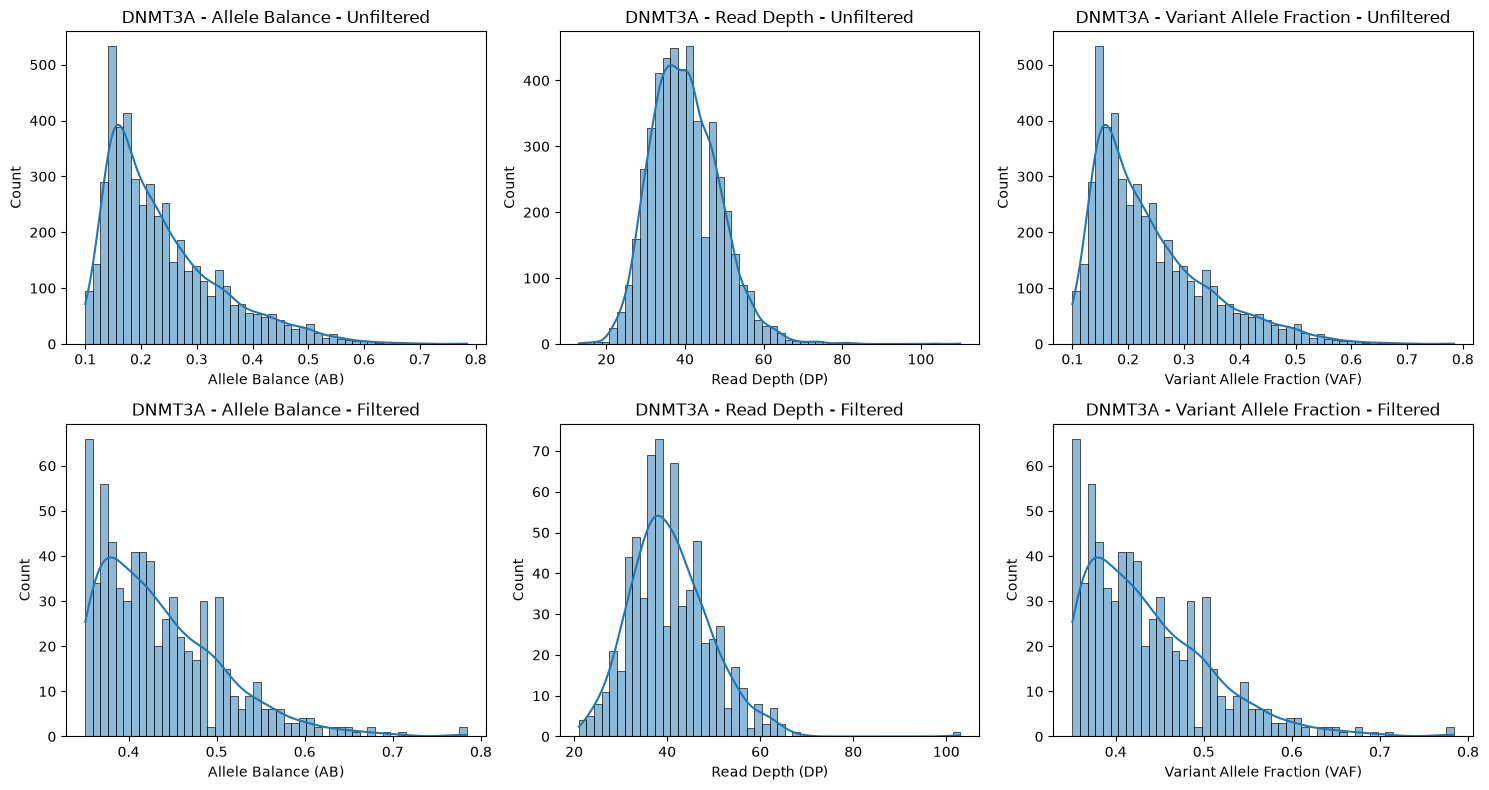

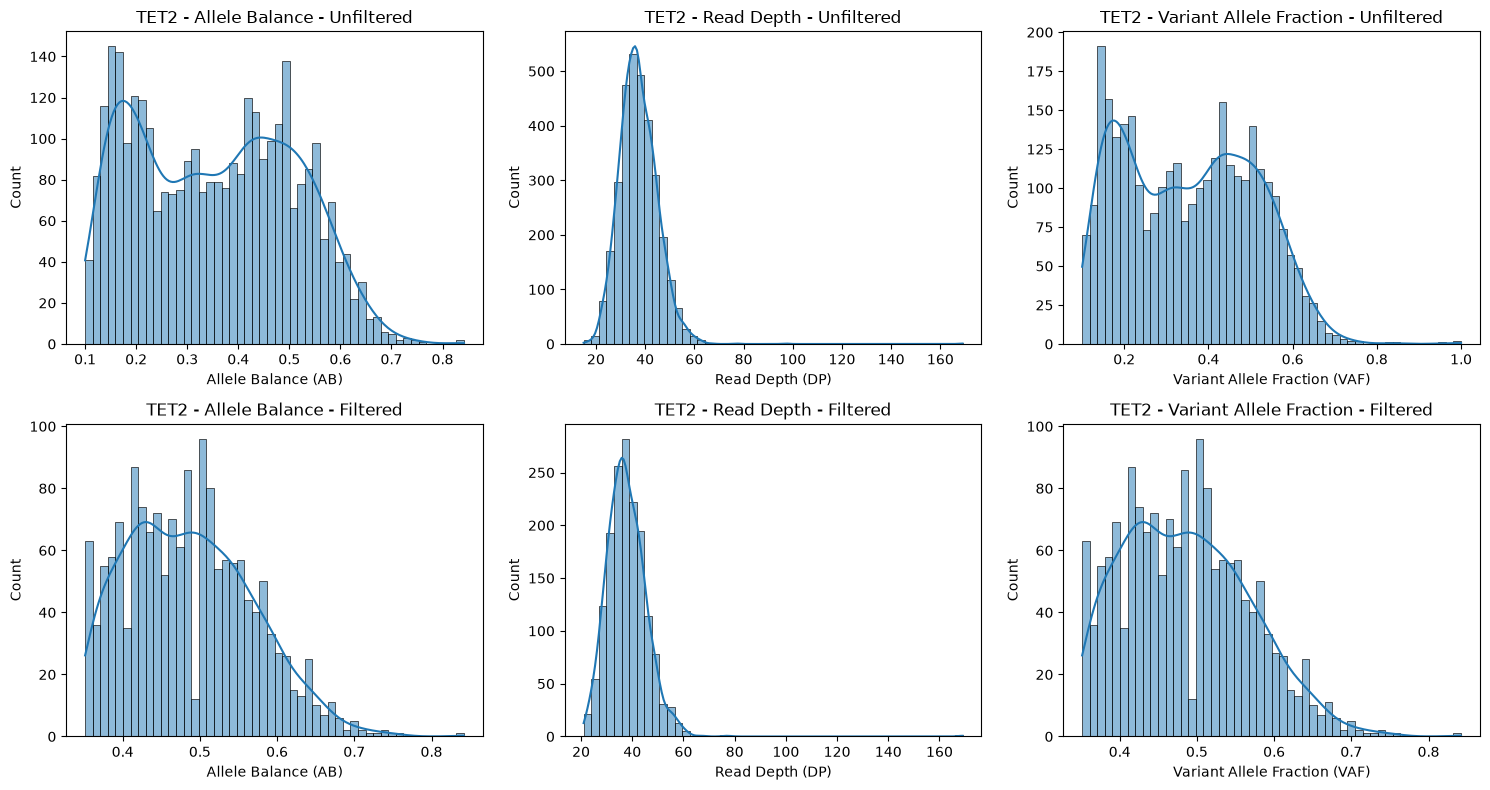

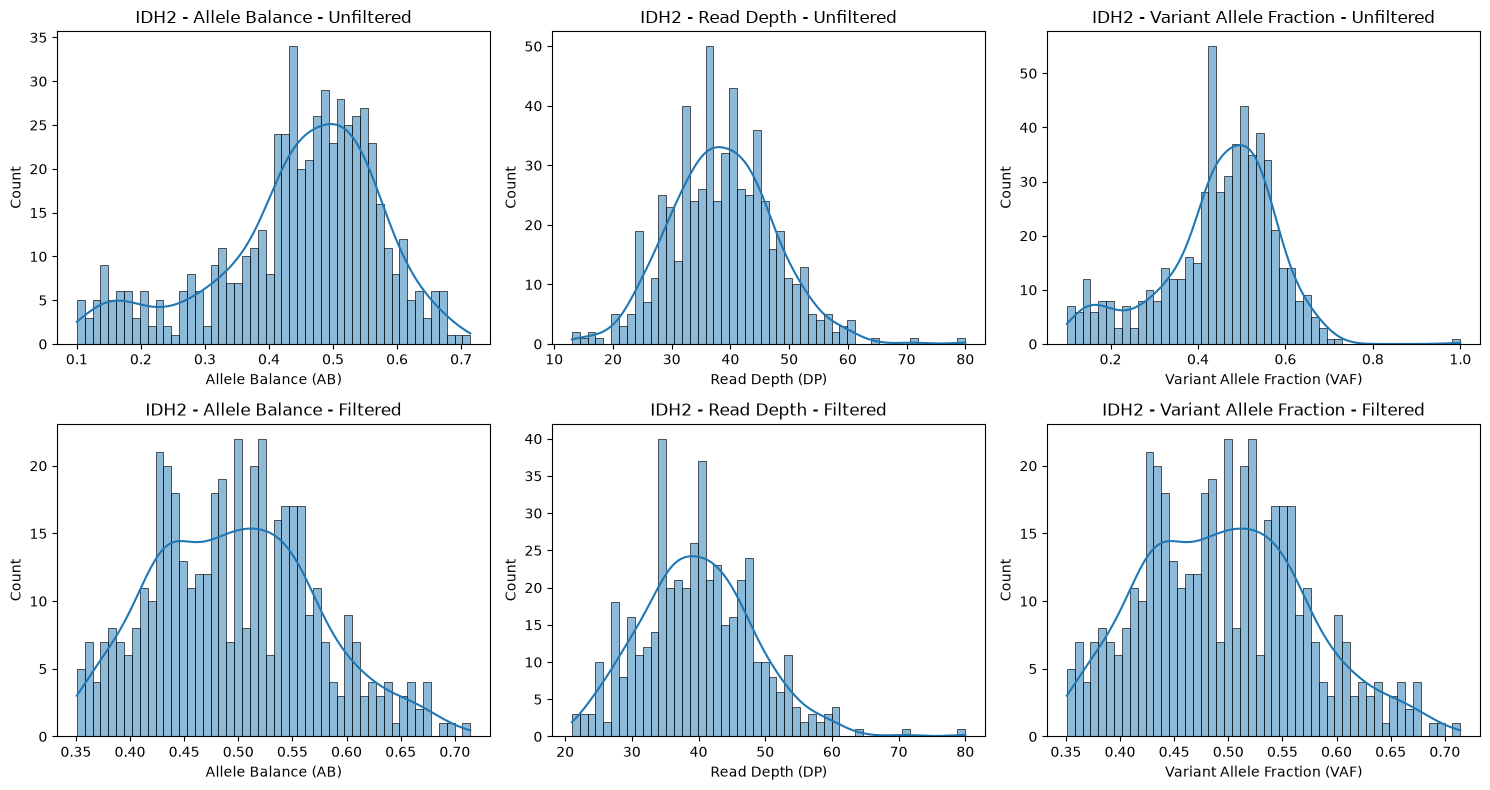

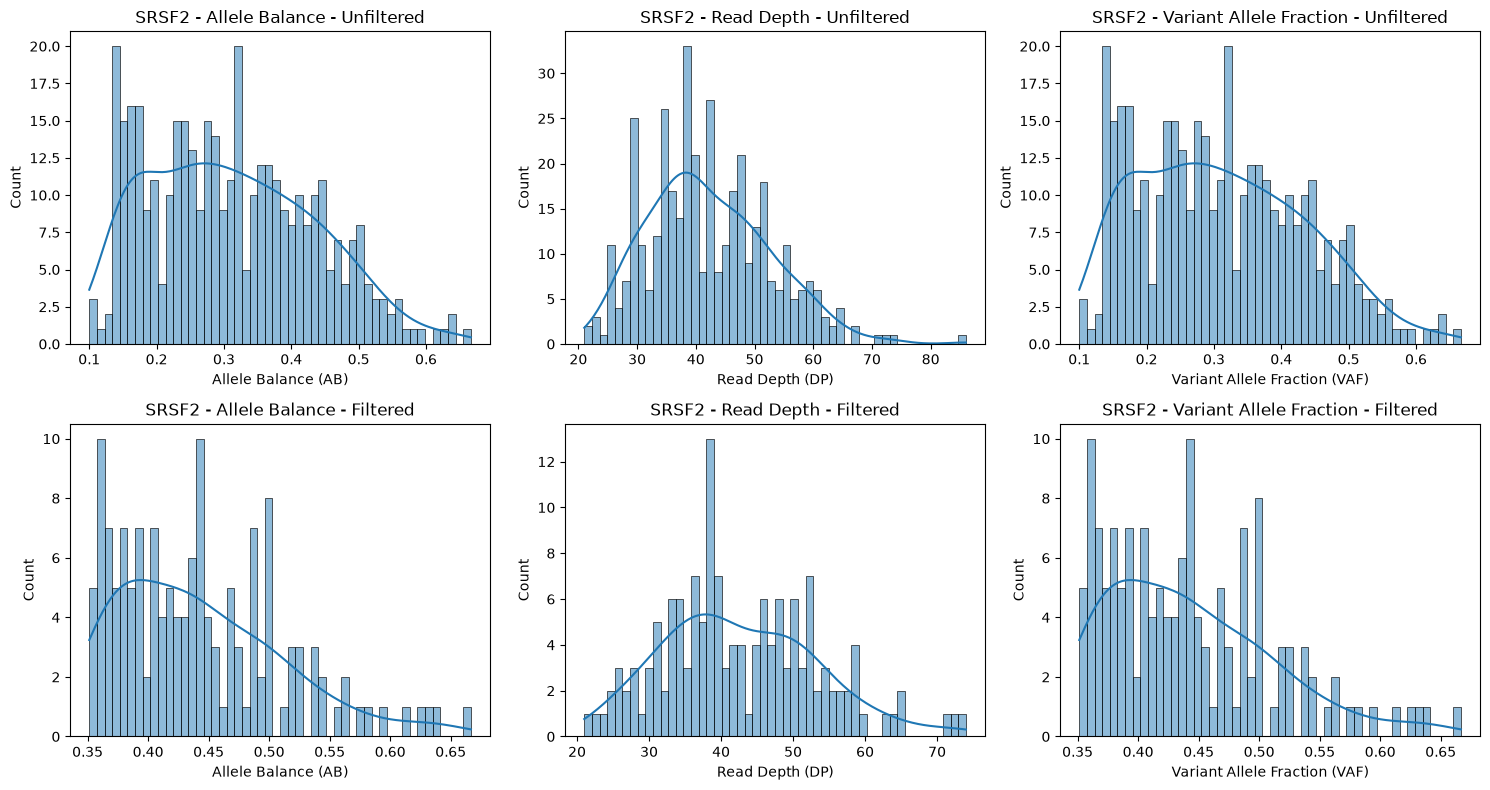

In [5]:
# Load pacakges 
import seaborn as sns
import matplotlib.pyplot as plt

# Filter for loss of function 
combined_subset_qc = subset_qc[subset_qc['id'].isin(pd.concat([lof, missense])['var'])]
combined_filtered_qc = filtered_qc[filtered_qc['id'].isin(pd.concat([lof, missense])['var'])]

# Lists for loop  
cols = ["AB", "DP", "VAF"]
names = ["Allele Balance", "Read Depth", "Variant Allele Fraction"]
chroms = ['chr2:', 'chr4:', 'chr15:', 'chr17:']
symbols = ['DNMT3A', 'TET2', 'IDH2', 'SRSF2']

for chrom, symbol in zip(chroms, symbols):
    # Reset indices
    plot_data1 = combined_subset_qc.reset_index(drop=True)
    plot_data2 = combined_filtered_qc.reset_index(drop=True)

    plot_data1 = plot_data1[plot_data1['id'].str.contains(chrom)]
    plot_data2 = plot_data2[plot_data2['id'].str.contains(chrom)]
    
    fig, axes = plt.subplots(
        2, 3,
        figsize=(15, 8)
    )
    
    # Top row plot 
    for ax, col, name in zip(axes[0], cols, names):
        sns.histplot(
            data=plot_data1,
            x=col,
            bins=50,
            kde=True,
            ax=ax
        )
        
        ax.set_title(f"{symbol} - {name} - Unfiltered")
        ax.set_xlabel(f'{name} ({col})')
        ax.set_ylabel("Count")
    
    # Bottom row plot 
    for ax, col, name in zip(axes[1], cols, names):
        sns.histplot(
            data=plot_data2,
            x=col,
            bins=50,
            kde=True,
            ax=ax
        )
        
        ax.set_title(f"{symbol} - {name} - Filtered")
        ax.set_xlabel(f'{name} ({col})')
        ax.set_ylabel("Count")
    
    plt.tight_layout()

    # Save PNG
    plt.savefig(f"QC_{symbol}_distributions.png", dpi=300, bbox_inches="tight")
    # Save PDF
    plt.savefig(f"QC_{symbol}_distributions.pdf", bbox_inches="tight")
    
    plt.show()

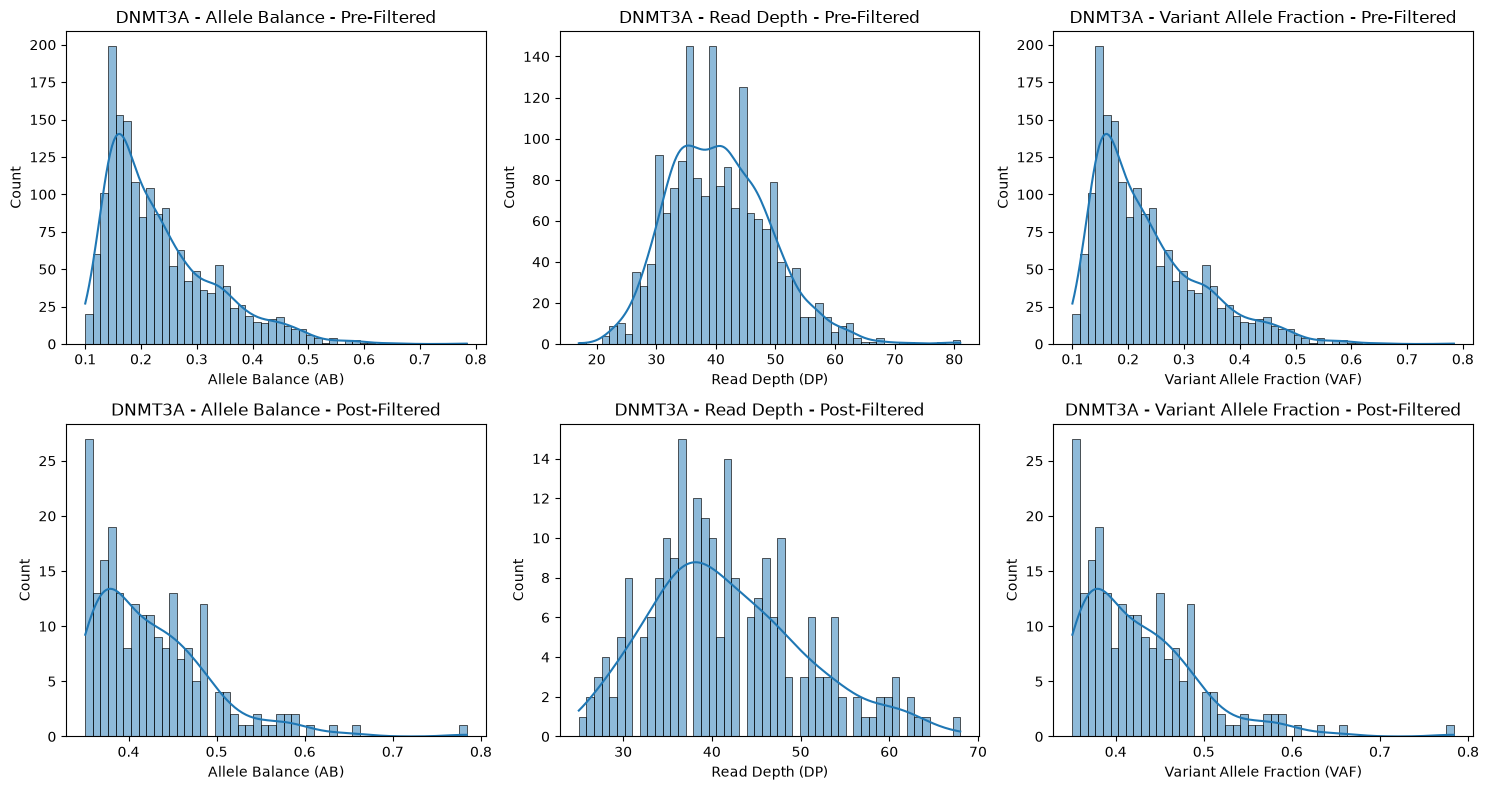

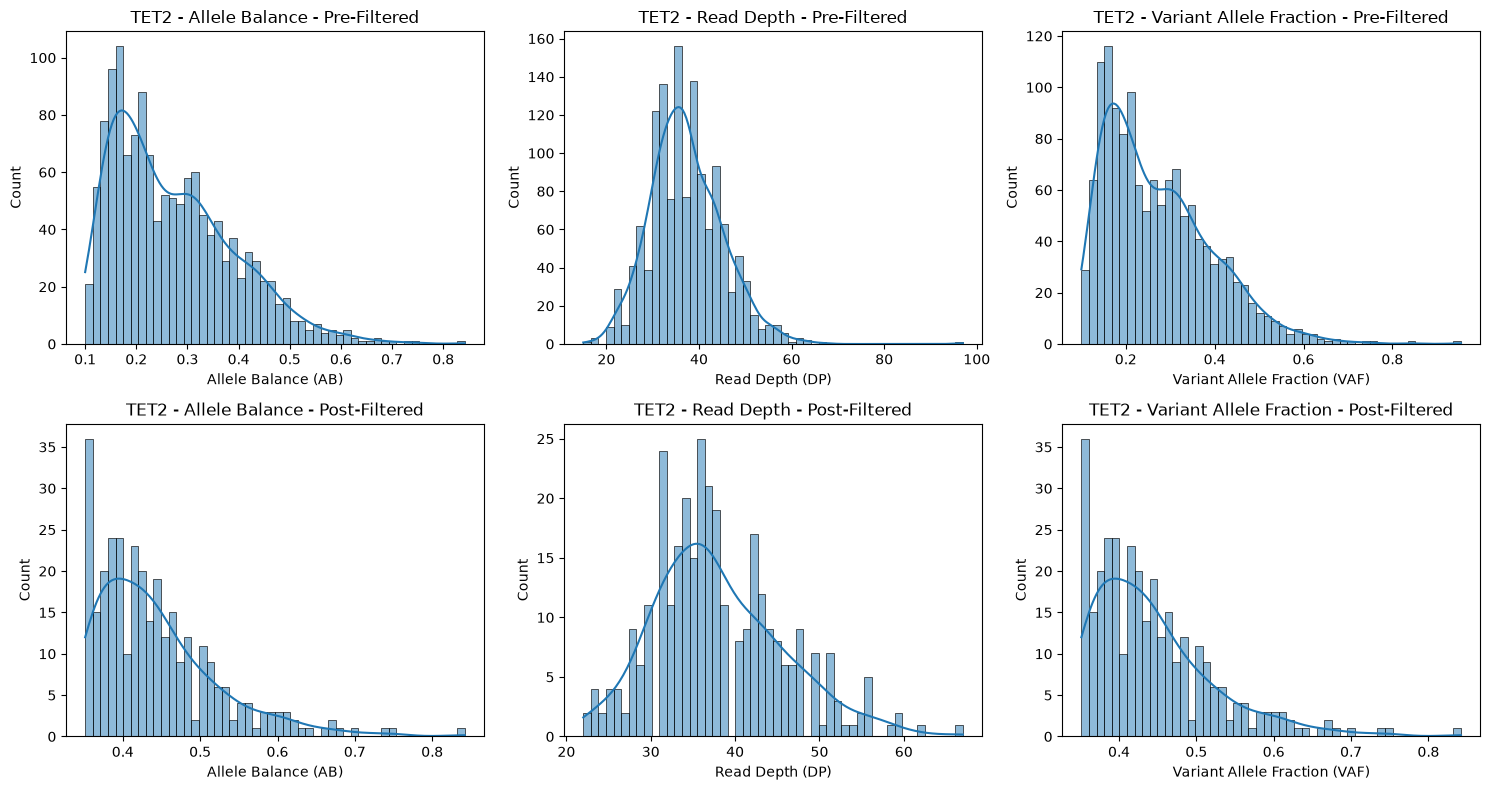

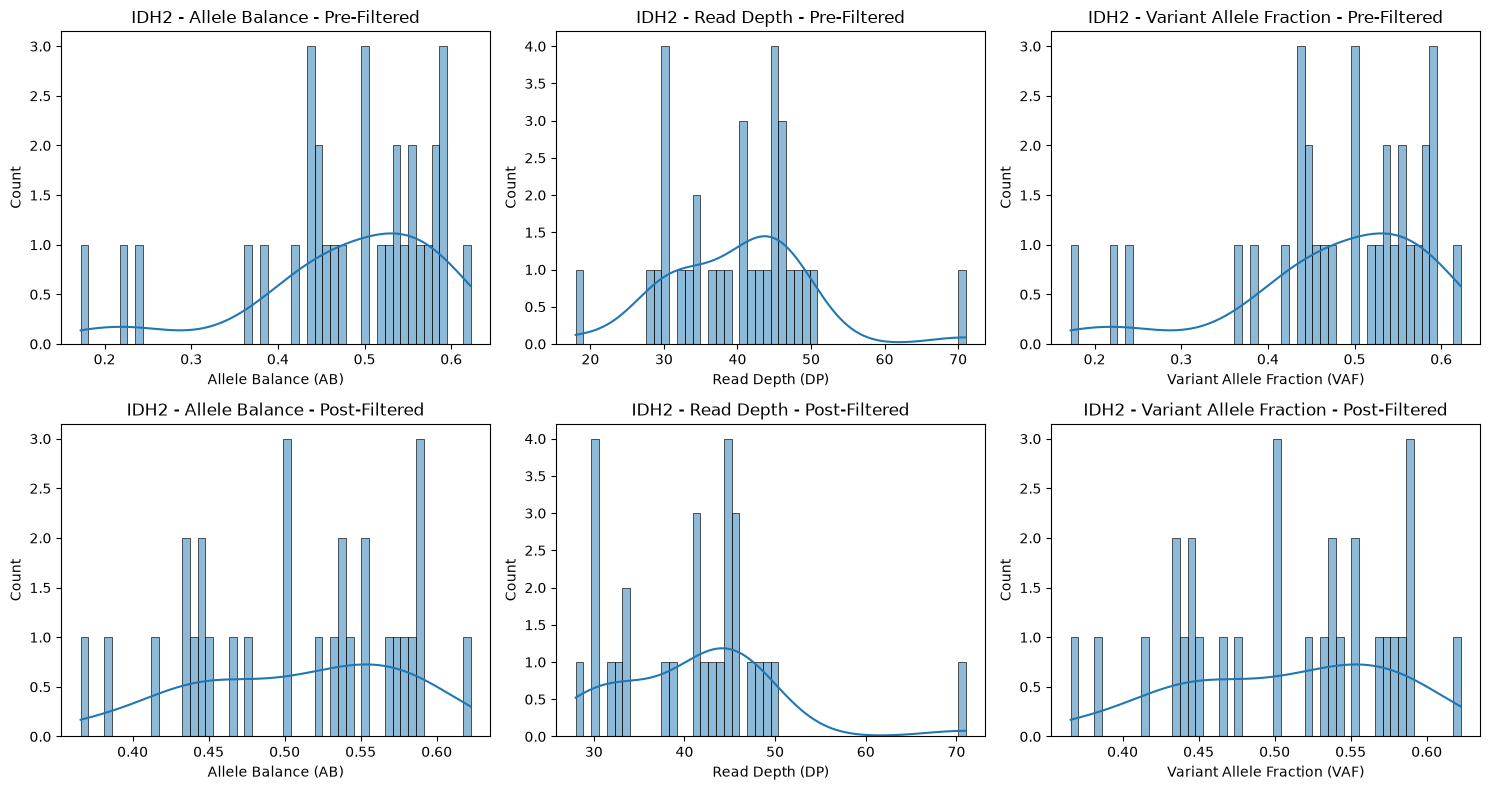

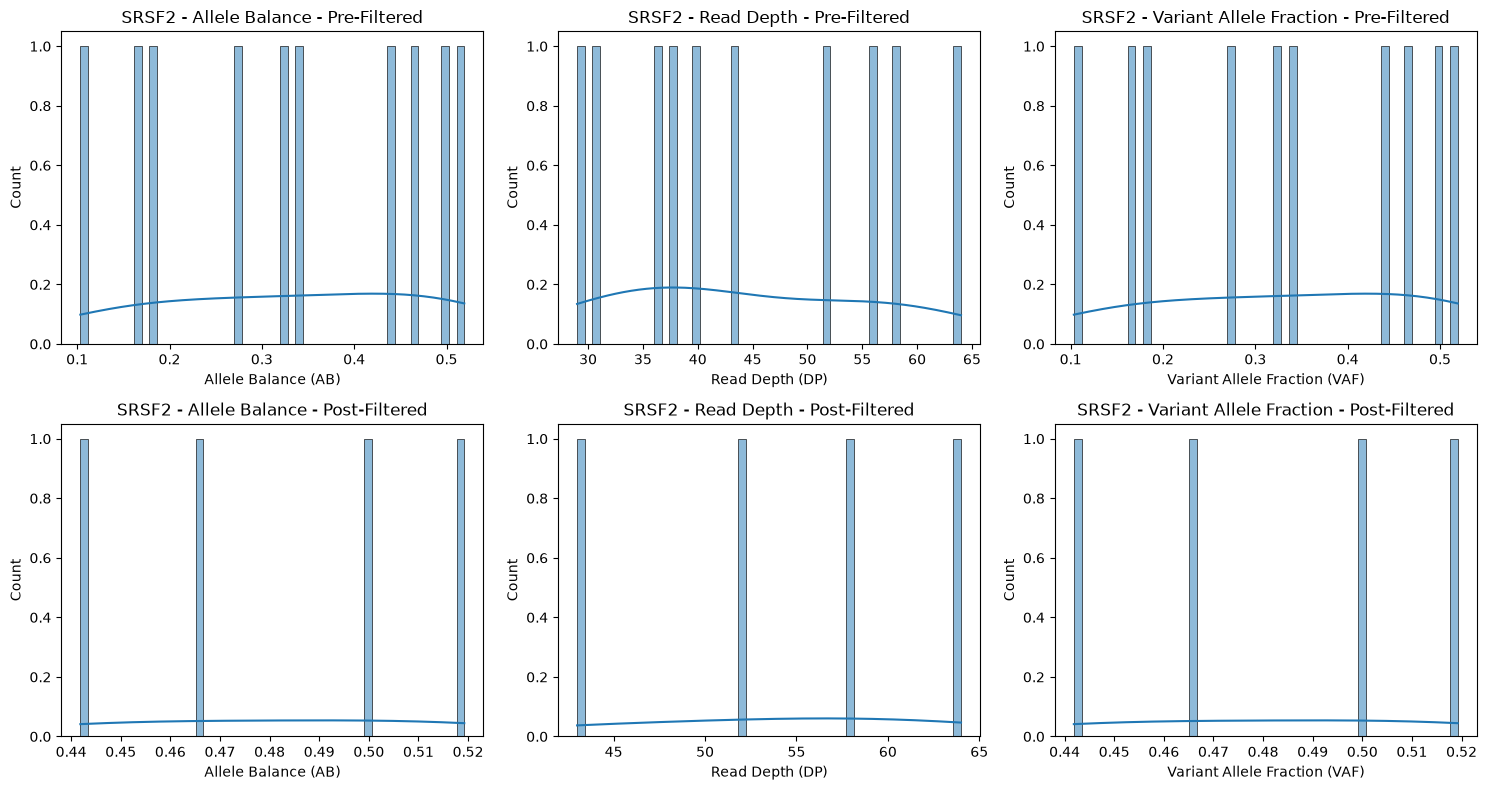

In [6]:
# Load pacakges 
import seaborn as sns
import matplotlib.pyplot as plt

# Filter for loss of function 
lof_subset_qc = subset_qc[subset_qc['id'].isin(lof['var'])]
lof_filtered_qc = filtered_qc[filtered_qc['id'].isin(lof['var'])]

# Lists for loop  
cols = ["AB", "DP", "VAF"]
names = ["Allele Balance", "Read Depth", "Variant Allele Fraction"]
chroms = ['chr2:', 'chr4:', 'chr15:', 'chr17:']
symbols = ['DNMT3A', 'TET2', 'IDH2', 'SRSF2']

for chrom, symbol in zip(chroms, symbols):
    # Reset indices
    plot_data1 = lof_subset_qc.reset_index(drop=True)
    plot_data2 = lof_filtered_qc.reset_index(drop=True)

    plot_data1 = plot_data1[plot_data1['id'].str.contains(chrom)]
    plot_data2 = plot_data2[plot_data2['id'].str.contains(chrom)]
    
    fig, axes = plt.subplots(
        2, 3,
        figsize=(15, 8)
    )
    
    # Top row plot 
    for ax, col, name in zip(axes[0], cols, names):
        sns.histplot(
            data=plot_data1,
            x=col,
            bins=50,
            kde=True,
            ax=ax
        )
        
        ax.set_title(f"{symbol} - {name} - Pre-Filtered")
        ax.set_xlabel(f'{name} ({col})')
        ax.set_ylabel("Count")
    
    # Bottom row plot 
    for ax, col, name in zip(axes[1], cols, names):
        sns.histplot(
            data=plot_data2,
            x=col,
            bins=50,
            kde=True,
            ax=ax
        )
        
        ax.set_title(f"{symbol} - {name} - Post-Filtered")
        ax.set_xlabel(f'{name} ({col})')
        ax.set_ylabel("Count")
    
    plt.tight_layout()

    # Save PNG
    plt.savefig(f"LoF_QC_{symbol}_distributions.png", dpi=300, bbox_inches="tight")
    # Save PDF
    plt.savefig(f"LoF_QC_{symbol}_distributions.pdf", bbox_inches="tight")
    
    plt.show()

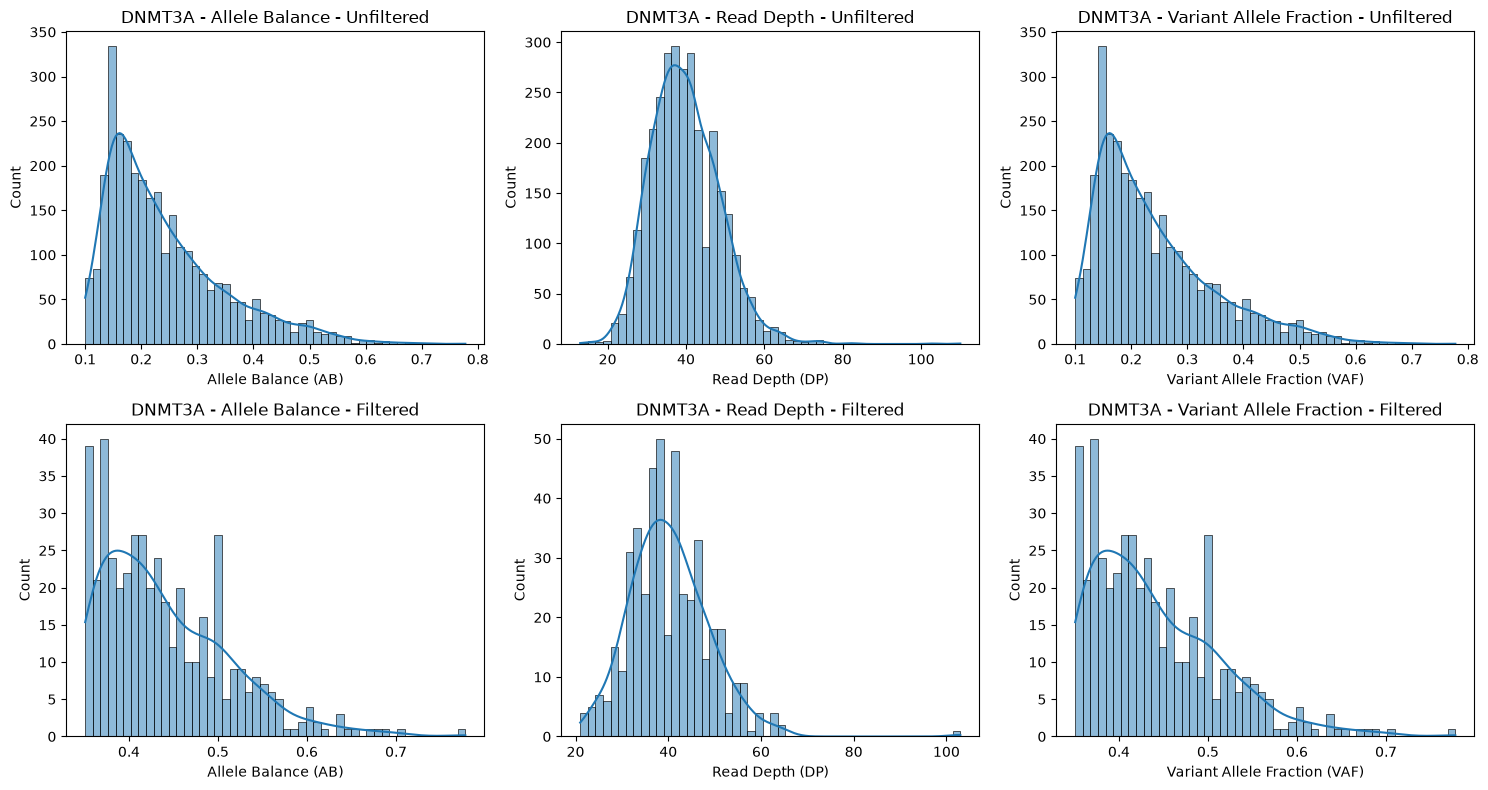

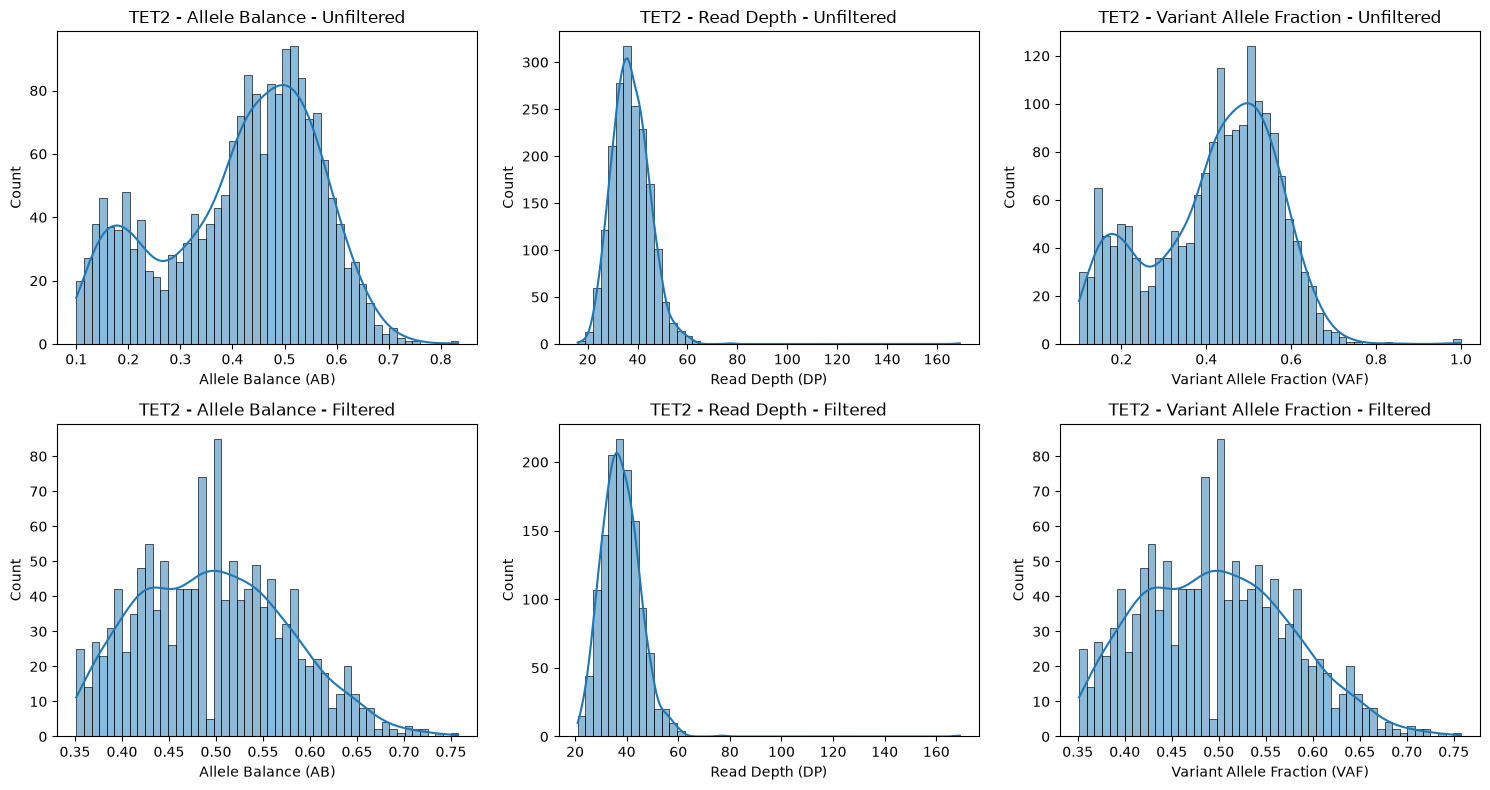

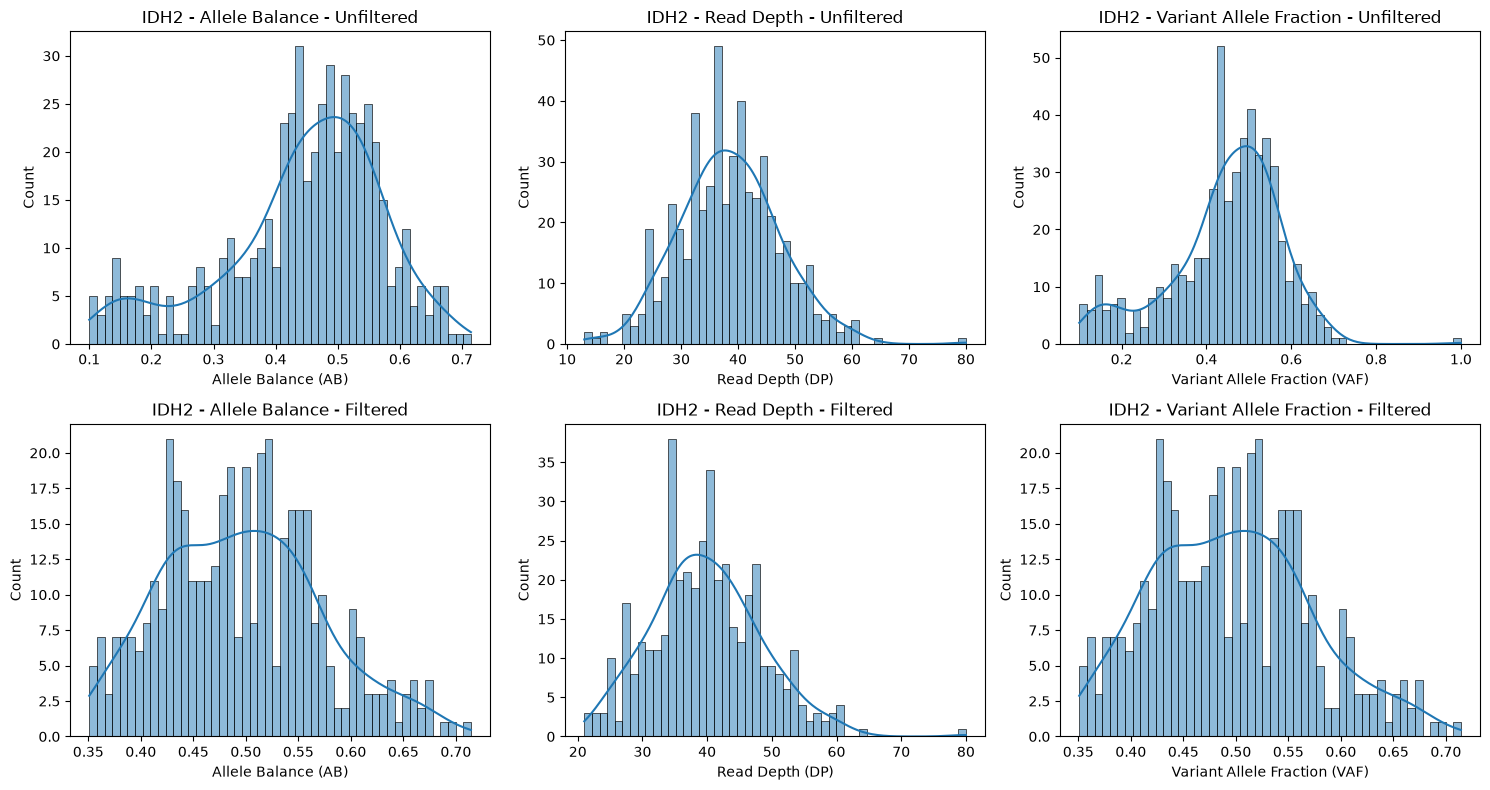

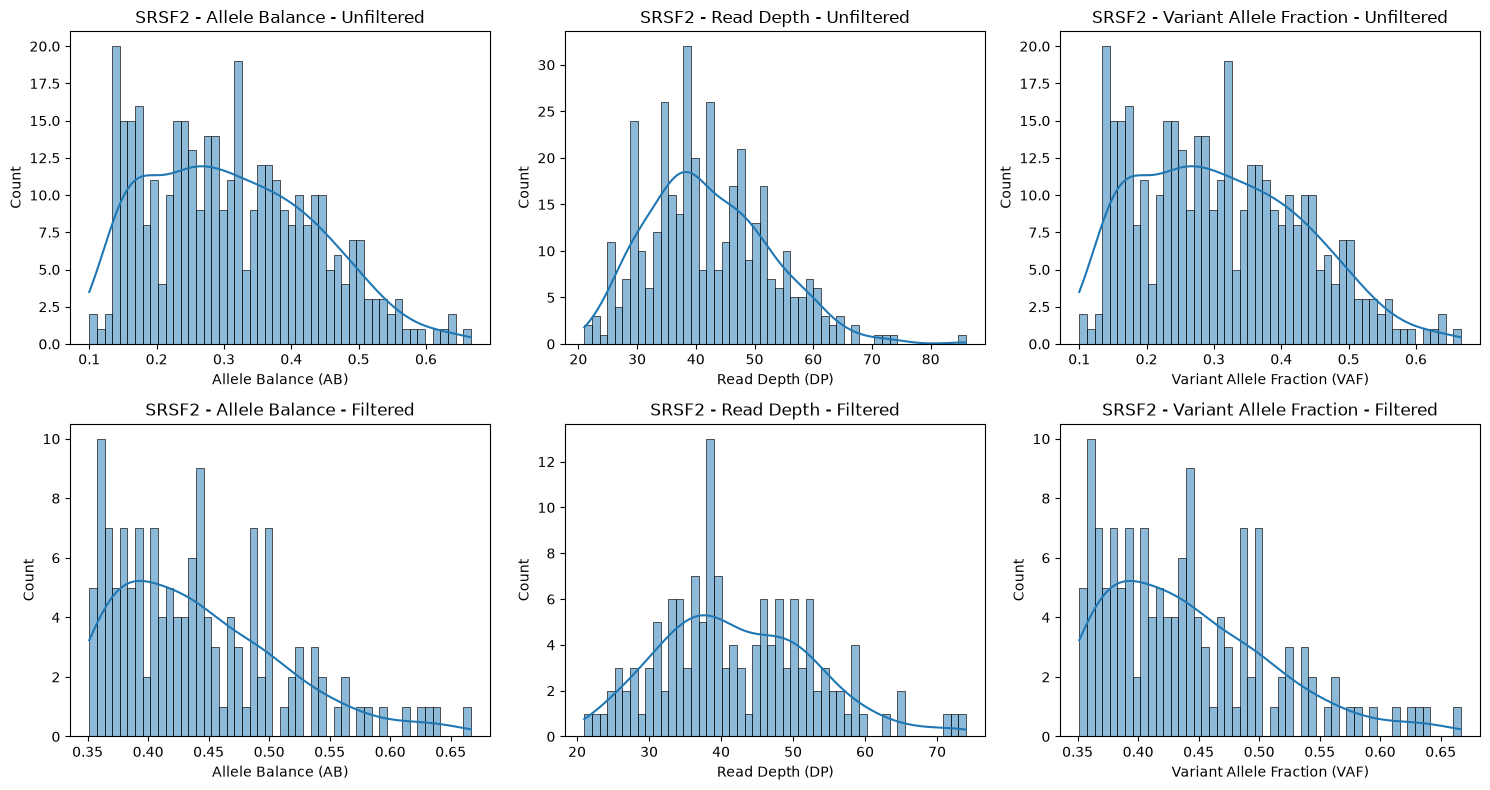

In [7]:
# Load pacakges 
import seaborn as sns
import matplotlib.pyplot as plt

# Filter for loss of function 
missense_subset_qc = subset_qc[subset_qc['id'].isin(missense['var'])]
missense_filtered_qc = filtered_qc[filtered_qc['id'].isin(missense['var'])]

# Lists for loop  
cols = ["AB", "DP", "VAF"]
names = ["Allele Balance", "Read Depth", "Variant Allele Fraction"]
chroms = ['chr2:', 'chr4:', 'chr15:', 'chr17:']
symbols = ['DNMT3A', 'TET2', 'IDH2', 'SRSF2']

for chrom, symbol in zip(chroms, symbols):
    # Reset indices
    plot_data1 = missense_subset_qc.reset_index(drop=True)
    plot_data2 = missense_filtered_qc.reset_index(drop=True)

    plot_data1 = plot_data1[plot_data1['id'].str.contains(chrom)]
    plot_data2 = plot_data2[plot_data2['id'].str.contains(chrom)]
    
    fig, axes = plt.subplots(
        2, 3,
        figsize=(15, 8)
    )
    
    # Top row plot 
    for ax, col, name in zip(axes[0], cols, names):
        sns.histplot(
            data=plot_data1,
            x=col,
            bins=50,
            kde=True,
            ax=ax
        )
        
        ax.set_title(f"{symbol} - {name} - Unfiltered")
        ax.set_xlabel(f'{name} ({col})')
        ax.set_ylabel("Count")
    
    # Bottom row plot 
    for ax, col, name in zip(axes[1], cols, names):
        sns.histplot(
            data=plot_data2,
            x=col,
            bins=50,
            kde=True,
            ax=ax
        )
        
        ax.set_title(f"{symbol} - {name} - Filtered")
        ax.set_xlabel(f'{name} ({col})')
        ax.set_ylabel("Count")
    
    plt.tight_layout()

    # Save PNG
    plt.savefig(f"Missense_QC_{symbol}_distributions.png", dpi=300, bbox_inches="tight")
    # Save PDF
    plt.savefig(f"Missense_QC_{symbol}_distributions.pdf", bbox_inches="tight")
    
    plt.show()

In [8]:
# Calcuclate summary statistics 
summary = df.groupby('id').agg(
        Nsamples=('id', 'size'),
        meanAB=('AB', 'mean'),
        meanDP=('DP', 'mean'),
        meanVAF=('VAF', 'mean'),
        medianAB=('AB', 'median'),
        medianDP=('DP', 'median'),
        medianVAF=('VAF', 'median'),
        maximumAB=('AB', 'max'),
        maximumDP=('DP', 'max'),
        maximumVAF=('VAF', 'max'),
        minimumAB=('AB', 'min'),
        minimumDP=('DP', 'min'),
        minimumVAF=('VAF', 'min')
)

# Filter for at lest 20 samples 
summary = summary[summary['Nsamples'] > 20]
# Save QC file 
summary.to_csv('QC_summary.tsv', sep='\t')